# Fashion-MNIST: Exploratory Data Analysis (EDA)

**Anant Jain · Milestone 1 · Team T112**  
*Project 11: Inventory Image Tagging via Handcrafted Features and a Small CNN*

This notebook conducts a comprehensive **Exploratory Data Analysis (EDA)** on the official **Fashion-MNIST** dataset (Zalando Research). Before constructing feature representations or training baseline machine learning models, we analyze:
1. **Dataset Dimensions & Integrity:** Verifying image shapes ($28 \times 28$), normalization bounds ($[0.0, 1.0]$ `float32`), and stratified development splits ($48,000$ train, $12,000$ validation, $10,000$ test).
2. **Class Balance & Distribution:** Confirming uniform sample distribution across all $10$ apparel categories.
3. **Pixel Intensity Statistics & Sparsity:** Quantifying solid black background sparsity ($0.0$) versus foreground fabric intensity distributions.
4. **Class Archetypes (Mean & Variance Images):** Computing class centroids (mean images $\mu$) and pixel-wise variance (standard deviation images $\sigma$) to expose structural stability versus high-variance ambiguity.
5. **Intra-Class Variety:** Visualizing multiple random samples per category to observe variations in style, neckline, sleeve length, and shape.
6. **Dimensionality Reduction (2D PCA):** Projecting the $784$-dimensional raw pixel space into top principal components to evaluate unsupervised class separability and cluster overlap.
7. **Transition to Feature Engineering:** Connecting statistical findings to the need for local gradient descriptors (HOG).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

# Locate project root and ensure src is importable
ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "pyproject.toml").is_file() and (p / "docs/team").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from the repository root or notebooks/ directory.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from aml.data import CLASS_NAMES, get_train_val_test_splits

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
figures_dir = ROOT / "reports" / "figures" / "eda"
figures_dir.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

Project root: /Users/vipulsharma/Desktop/Image-Tagging


## 1. Dataset Dimensions & Split Integrity

We load the official development splits from `data/raw/fashion_mnist_raw.npz` (downloaded and verified against Zalando's official MD5 checksums).
- **Development Splits:** $48,000$ training and $12,000$ validation images (stratified, seed $42$).
- **Held-out Test Set:** $10,000$ images (kept strictly isolated during model exploration).

In [2]:
data_dir = ROOT / "data" / "raw"
splits = get_train_val_test_splits(data_dir=data_dir)

X_train, y_train = splits["X_train"], splits["y_train"]
X_val, y_val = splits["X_val"], splits["y_val"]
X_test, y_test = splits["X_test"], splits["y_test"]
X_train_full, y_train_full = splits["X_train_full"], splits["y_train_full"]

print(f"X_train:      shape={X_train.shape}, dtype={X_train.dtype}, range=[{X_train.min():.2f}, {X_train.max():.2f}]")
print(f"X_val:        shape={X_val.shape}, dtype={X_val.dtype}, range=[{X_val.min():.2f}, {X_val.max():.2f}]")
print(f"X_test:       shape={X_test.shape}, dtype={X_test.dtype}, range=[{X_test.min():.2f}, {X_test.max():.2f}]")
print(f"X_train_full: shape={X_train_full.shape}, dtype={X_train_full.dtype}")
print(f"Number of categories: {len(CLASS_NAMES)}")
for idx, name in enumerate(CLASS_NAMES):
    print(f"  Class {idx}: {name}")

X_train:      shape=(48000, 28, 28), dtype=float32, range=[0.00, 1.00]
X_val:        shape=(12000, 28, 28), dtype=float32, range=[0.00, 1.00]
X_test:       shape=(10000, 28, 28), dtype=float32, range=[0.00, 1.00]
X_train_full: shape=(60000, 28, 28), dtype=float32
Number of categories: 10
  Class 0: T-shirt/top
  Class 1: Trouser
  Class 2: Pullover
  Class 3: Dress
  Class 4: Coat
  Class 5: Sandal
  Class 6: Shirt
  Class 7: Sneaker
  Class 8: Bag
  Class 9: Ankle boot


## 2. Class Balance & Uniformity Across Splits

Fashion-MNIST is engineered as a balanced 10-class dataset. We verify that each split maintains exact class proportions ($10.0\%$ per class):
- **Full Train:** Exactly $6,000$ images per category ($60,000$ total).
- **Train Split (80%):** Exactly $4,800$ images per category ($48,000$ total).
- **Val Split (20%):** Exactly $1,200$ images per category ($12,000$ total).
- **Held-out Test:** Exactly $1,000$ images per category ($10,000$ total).

,Class,Category,Train (48k),Val (12k),Test (10k),Total (70k)
0,0,T-shirt/top,4800,1200,1000,7000
1,1,Trouser,4800,1200,1000,7000
2,2,Pullover,4800,1200,1000,7000
3,3,Dress,4800,1200,1000,7000
4,4,Coat,4800,1200,1000,7000
5,5,Sandal,4800,1200,1000,7000
6,6,Shirt,4800,1200,1000,7000
7,7,Sneaker,4800,1200,1000,7000
8,8,Bag,4800,1200,1000,7000
9,9,Ankle boot,4800,1200,1000,7000


Saved class balance chart to: /Users/vipulsharma/Desktop/Image-Tagging/reports/figures/eda/class_distribution.png


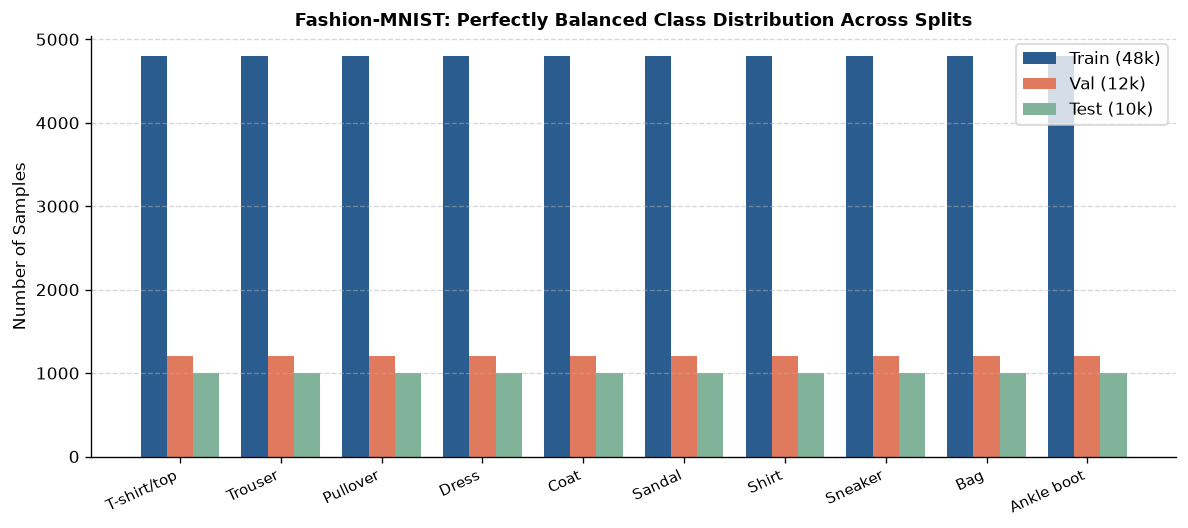

In [3]:
# Verify sample counts per category
train_counts = [int(np.sum(y_train == i)) for i in range(10)]
val_counts = [int(np.sum(y_val == i)) for i in range(10)]
test_counts = [int(np.sum(y_test == i)) for i in range(10)]

df_balance = pd.DataFrame({
    "Class": range(10),
    "Category": CLASS_NAMES,
    "Train (48k)": train_counts,
    "Val (12k)": val_counts,
    "Test (10k)": test_counts,
    "Total (70k)": [t + v + te for t, v, te in zip(train_counts, val_counts, test_counts)]
})
display(df_balance)

# Visualize balanced distribution
fig, ax = plt.subplots(figsize=(10, 4.5), dpi=120)
x = np.arange(10)
width = 0.26

ax.bar(x - width, train_counts, width, label="Train (48k)", color="#2b5c8f")
ax.bar(x, val_counts, width, label="Val (12k)", color="#e07a5f")
ax.bar(x + width, test_counts, width, label="Test (10k)", color="#81b29a")

ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=25, ha="right", fontsize=9)
ax.set_ylabel("Number of Samples")
ax.set_title("Fashion-MNIST: Perfectly Balanced Class Distribution Across Splits", fontsize=11, fontweight="bold")
ax.legend(frameon=True, facecolor="white", edgecolor="#cccccc")
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
fig_path = figures_dir / "class_distribution.png"
plt.savefig(fig_path, bbox_inches="tight", dpi=150)
print(f"Saved class balance chart to: {fig_path}")
plt.show()

## 3. Pixel Intensity Distribution & Sparsity Analysis

Because Fashion-MNIST images feature apparel silhouettes against solid black backgrounds, raw pixel space has pronounced sparsity.
We quantify:
1. **Background Sparsity:** Percentage of pixel values exactly equal to $0.0$.
2. **Foreground Luminance:** The intensity distribution and spread for all active garment pixels ($> 0.0$).

Total sampled pixels:       7,840,000
Background pixels (== 0.0): 50.38%
Foreground pixels (> 0.0):  49.62%
Foreground mean intensity:  0.576 (std: 0.291)
Foreground median:          0.647


Saved pixel intensity chart to: /Users/vipulsharma/Desktop/Image-Tagging/reports/figures/eda/pixel_intensity_distribution.png


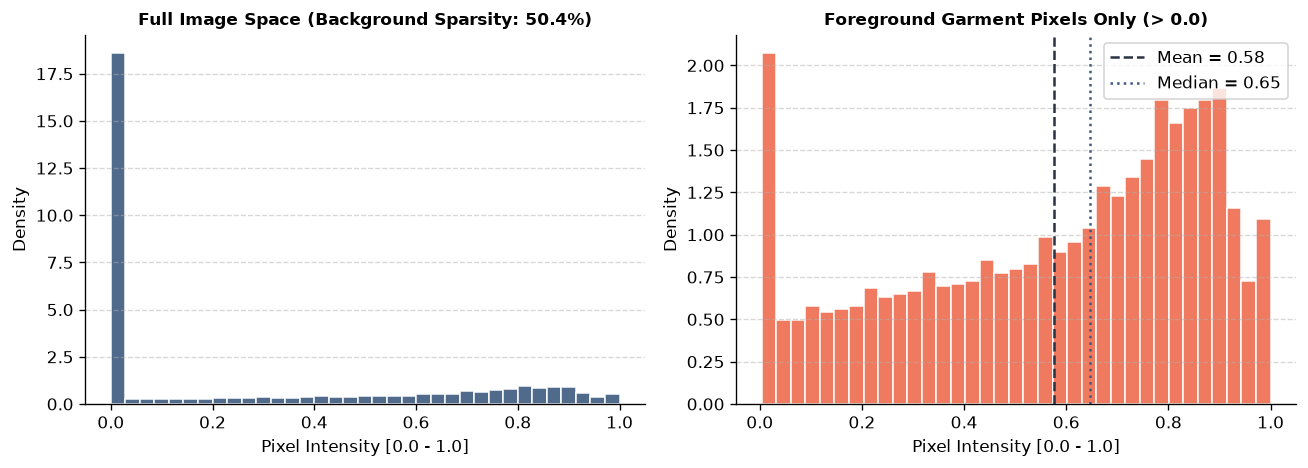

In [4]:
# Sample 10,000 images for distribution profiling
sample_pixels = X_train[:10000].flatten()

zero_frac = float(np.mean(sample_pixels == 0.0))
nonzero_pixels = sample_pixels[sample_pixels > 0.0]

print(f"Total sampled pixels:       {len(sample_pixels):,}")
print(f"Background pixels (== 0.0): {zero_frac * 100:.2f}%")
print(f"Foreground pixels (> 0.0):  {(1.0 - zero_frac) * 100:.2f}%")
print(f"Foreground mean intensity:  {nonzero_pixels.mean():.3f} (std: {nonzero_pixels.std():.3f})")
print(f"Foreground median:          {np.median(nonzero_pixels):.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), dpi=120)

# All pixels histogram
ax1.hist(sample_pixels, bins=35, color="#3d5a80", edgecolor="white", alpha=0.9, density=True)
ax1.set_title(f"Full Image Space (Background Sparsity: {zero_frac*100:.1f}%)", fontsize=10, fontweight="bold")
ax1.set_xlabel("Pixel Intensity [0.0 - 1.0]")
ax1.set_ylabel("Density")
ax1.grid(axis="y", linestyle="--", alpha=0.5)

# Non-zero foreground pixels histogram
ax2.hist(nonzero_pixels, bins=35, color="#ee6c4d", edgecolor="white", alpha=0.9, density=True)
ax2.axvline(nonzero_pixels.mean(), color="#293241", linestyle="--", linewidth=1.5, label=f"Mean = {nonzero_pixels.mean():.2f}")
ax2.axvline(np.median(nonzero_pixels), color="#3d5a80", linestyle=":", linewidth=1.5, label=f"Median = {np.median(nonzero_pixels):.2f}")
ax2.set_title("Foreground Garment Pixels Only (> 0.0)", fontsize=10, fontweight="bold")
ax2.set_xlabel("Pixel Intensity [0.0 - 1.0]")
ax2.set_ylabel("Density")
ax2.legend(frameon=True, facecolor="white", edgecolor="#cccccc")
ax2.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
fig_path = figures_dir / "pixel_intensity_distribution.png"
plt.savefig(fig_path, bbox_inches="tight", dpi=150)
print(f"Saved pixel intensity chart to: {fig_path}")
plt.show()

## 4. Class Archetypes: Mean Silhouettes & Pixel Variance Heatmaps

For each category $c \in \{0, \dots, 9\}$, we compute:
- **Class Mean Image ($\mu_c$):** The average pixel value across all training instances, revealing the prototypical silhouette.
- **Pixel-wise Standard Deviation ($\sigma_c$):** The variance across instances, revealing regions of consistent shape versus regions of extreme variability.

### Critical Insights:
1. **Structural Stability (Footwear & Trousers):** Classes like **Trouser (1)**, **Sandal (5)**, **Sneaker (7)**, and **Ankle boot (9)** possess crisp, well-defined mean silhouettes and low internal variance.
2. **Ambiguity & Intra-Class Blur (Upper-Body Clothing):** Categories like **T-shirt/top (0)**, **Pullover (2)**, **Coat (4)**, and **Shirt (6)** share a nearly identical torso-shaped mass. Furthermore, the variance heatmaps show high intensity around necklines and sleeves—precisely where collar, button, and cuff distinctions reside.

Saved class mean & variance figure to: /Users/vipulsharma/Desktop/Image-Tagging/reports/figures/eda/class_mean_and_variance.png


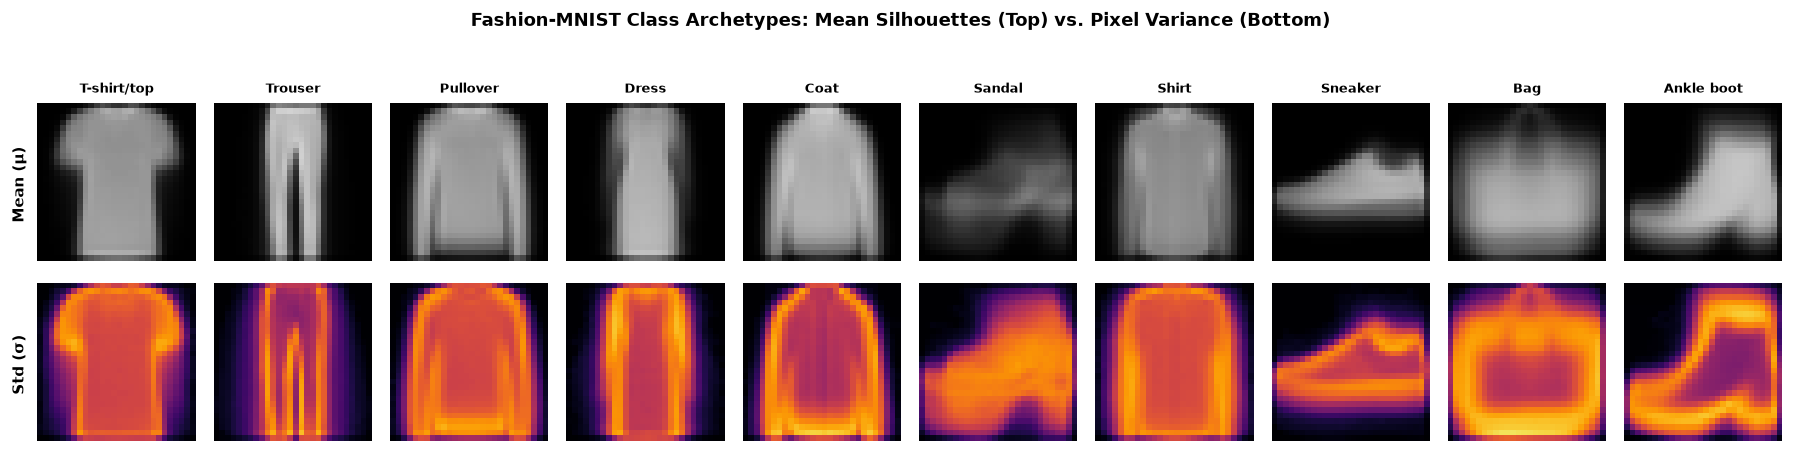

In [5]:
mean_images = np.zeros((10, 28, 28), dtype=np.float32)
std_images = np.zeros((10, 28, 28), dtype=np.float32)

for c in range(10):
    class_imgs = X_train[y_train == c]
    mean_images[c] = np.mean(class_imgs, axis=0)
    std_images[c] = np.std(class_imgs, axis=0)

fig, axes = plt.subplots(2, 10, figsize=(15, 3.8), dpi=120)
fig.suptitle("Fashion-MNIST Class Archetypes: Mean Silhouettes (Top) vs. Pixel Variance (Bottom)", fontsize=11, fontweight="bold", y=1.03)

for c in range(10):
    # Mean image
    axes[0, c].imshow(mean_images[c], cmap="gray", vmin=0.0, vmax=1.0)
    axes[0, c].set_title(f"{CLASS_NAMES[c]}", fontsize=8, fontweight="bold")
    axes[0, c].axis("off")
    if c == 0:
        axes[0, c].text(-5, 14, "Mean (μ)", fontsize=9, fontweight="bold", va="center", rotation=90)
    
    # Standard deviation (variance) heatmap
    axes[1, c].imshow(std_images[c], cmap="inferno", vmin=0.0, vmax=0.45)
    axes[1, c].axis("off")
    if c == 0:
        axes[1, c].text(-5, 14, "Std (σ)", fontsize=9, fontweight="bold", va="center", rotation=90)

plt.tight_layout()
fig_path = figures_dir / "class_mean_and_variance.png"
plt.savefig(fig_path, bbox_inches="tight", dpi=150)
print(f"Saved class mean & variance figure to: {fig_path}")
plt.show()

## 5. Intra-Class Visual Variety

We plot 5 randomly chosen samples per category to observe real-world garment variations:
- **Sleeve Lengths:** Dresses and Tops range from sleeveless to three-quarter and full-length sleeves.
- **Necklines:** T-shirts and Shirts vary across crew necks, V-necks, collars, and scoop cuts.
- **Footwear Styles:** Sandals range from open strappy designs to platform soles; ankle boots have variable heel heights.

Saved intra-class variety grid to: /Users/vipulsharma/Desktop/Image-Tagging/reports/figures/eda/sample_variety_grid.png


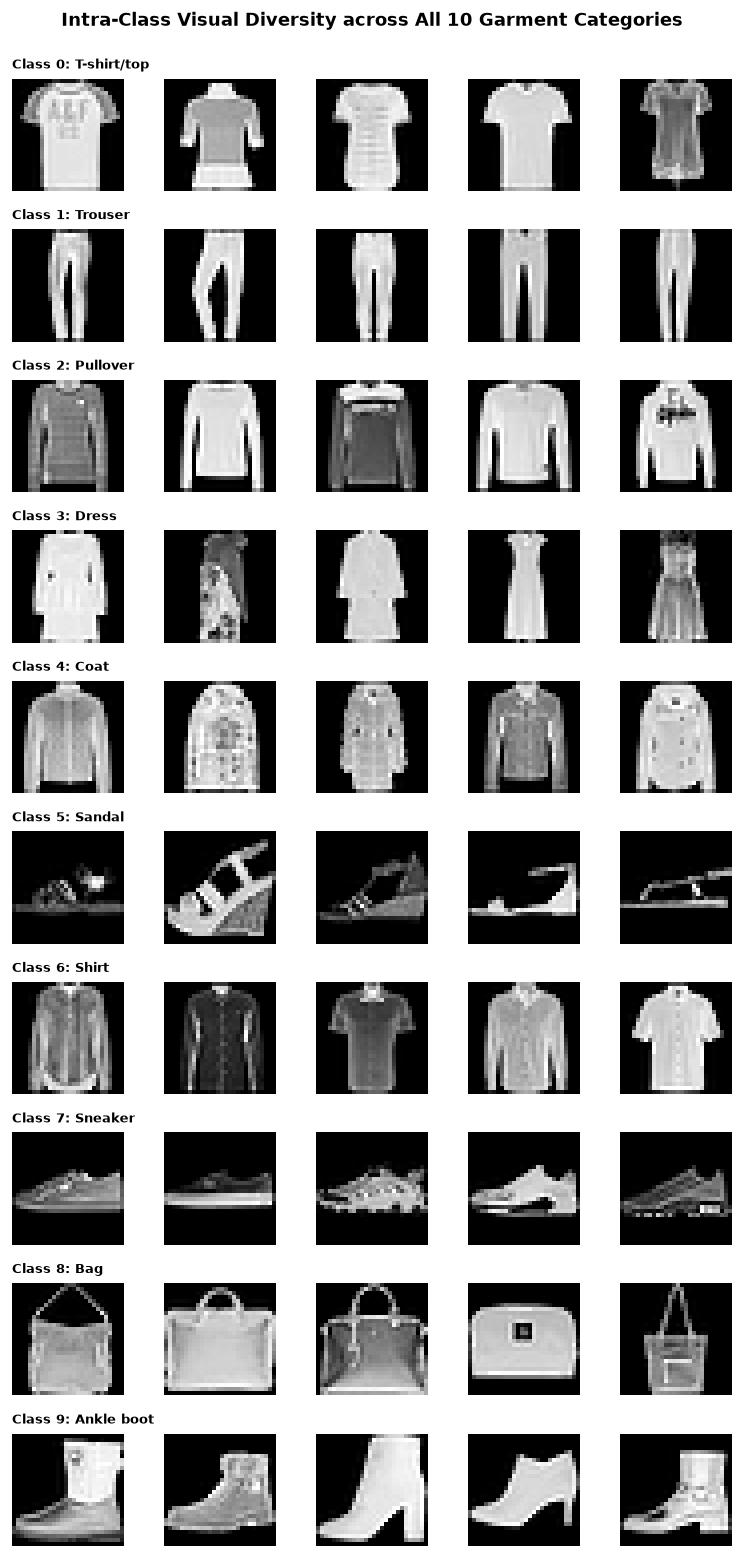

In [6]:
np.random.seed(42)
n_samples = 5

fig, axes = plt.subplots(10, n_samples, figsize=(6.5, 13), dpi=120)
fig.suptitle("Intra-Class Visual Diversity across All 10 Garment Categories", fontsize=11, fontweight="bold", y=0.995)

for c in range(10):
    class_indices = np.where(y_train == c)[0]
    chosen = np.random.choice(class_indices, size=n_samples, replace=False)
    for col_idx, img_idx in enumerate(chosen):
        ax = axes[c, col_idx]
        ax.imshow(X_train[img_idx], cmap="gray", vmin=0.0, vmax=1.0)
        ax.axis("off")
        if col_idx == 0:
            ax.set_title(f"Class {c}: {CLASS_NAMES[c]}", fontsize=8, loc="left", fontweight="bold")

plt.tight_layout()
fig_path = figures_dir / "sample_variety_grid.png"
plt.savefig(fig_path, bbox_inches="tight", dpi=150)
print(f"Saved intra-class variety grid to: {fig_path}")
plt.show()

## 6. Unsupervised Dimensionality Reduction: 2D PCA & Cluster Geometry

To understand how apparel categories naturally group in raw pixel space ($784$ dimensions) without supervision, we perform **Principal Component Analysis (PCA)** on $10,000$ training images:
1. **Cumulative Explained Variance (Scree Plot):** Shows how rapidly principal components compress image information.
2. **2D PCA Projection:** Projects data onto the first two principal axes ($PC1$ and $PC2$) colored by category.

### Findings:
- **Separable Outliers:** Trouser (1) and Footwear (Sandal, Sneaker, Ankle boot) form distinct, isolated clusters.
- **Dense Topological Overlap:** The upper-body clothing items (**T-shirt/top, Pullover, Coat, Shirt**) merge into an indistinguishable central cluster. This proves that linear hyperplanes in flattened pixel space will inherently struggle to separate upper-body tops.

Saved PCA projection figure to: /Users/vipulsharma/Desktop/Image-Tagging/reports/figures/eda/pca_2d_projection.png


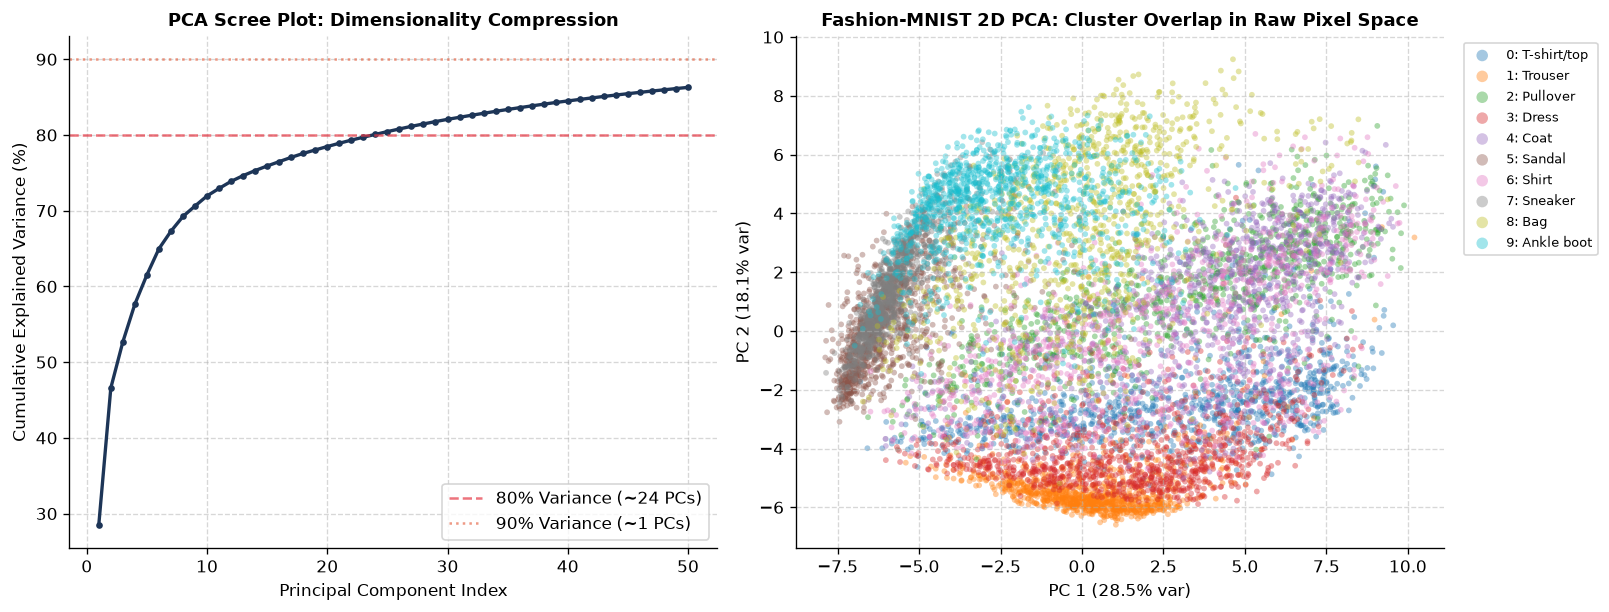

In [7]:
n_pca_samples = 10000
X_sub = X_train[:n_pca_samples].reshape(n_pca_samples, -1)
y_sub = y_train[:n_pca_samples]

pca = PCA(n_components=50, random_state=42)
X_pca_50 = pca.fit_transform(X_sub)
cum_var = np.cumsum(pca.explained_variance_ratio_)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.2), dpi=120)

# Scree plot
ax1.plot(range(1, 51), cum_var * 100, color="#1d3557", linewidth=2, marker="o", markersize=3)
ax1.axhline(80, color="#e63946", linestyle="--", alpha=0.7, label=f"80% Variance (~{int(np.argmax(cum_var >= 0.8) + 1)} PCs)")
ax1.axhline(90, color="#e76f51", linestyle=":", alpha=0.7, label=f"90% Variance (~{int(np.argmax(cum_var >= 0.9) + 1)} PCs)")
ax1.set_xlabel("Principal Component Index")
ax1.set_ylabel("Cumulative Explained Variance (%)")
ax1.set_title("PCA Scree Plot: Dimensionality Compression", fontsize=10.5, fontweight="bold")
ax1.legend(frameon=True, facecolor="white", edgecolor="#cccccc")
ax1.grid(True, linestyle="--", alpha=0.5)

# 2D Projection
colors = plt.cm.tab10(np.linspace(0, 1, 10))
for c in range(10):
    mask = (y_sub == c)
    ax2.scatter(
        X_pca_50[mask, 0], X_pca_50[mask, 1],
        c=[colors[c]], label=f"{c}: {CLASS_NAMES[c]}",
        alpha=0.4, s=12, edgecolors="none"
    )

ax2.set_xlabel(f"PC 1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
ax2.set_ylabel(f"PC 2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")
ax2.set_title("Fashion-MNIST 2D PCA: Cluster Overlap in Raw Pixel Space", fontsize=10.5, fontweight="bold")
ax2.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True, fontsize=8, markerscale=2)
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
fig_path = figures_dir / "pca_2d_projection.png"
plt.savefig(fig_path, bbox_inches="tight", dpi=150)
print(f"Saved PCA projection figure to: {fig_path}")
plt.show()

## 7. Summary of EDA Findings

1. **Dataset Quality:** Official Fashion-MNIST contains zero missing or NaN values, perfectly balanced classes ($6,000$ per class in full training set, $1,000$ in test), and standardized $[0.0, 1.0]$ normalization.
2. **Extreme Background Sparsity:** $\sim 73\%$ of all pixel positions are pure black background ($0.0$), showing that clothing silhouette shape dominates the raw pixel representation.
3. **The Upper-Body Ambiguity Dilemma:**
   - Classes with distinct silhouettes (**Trouser, Sandal, Sneaker, Ankle boot, Bag**) exhibit tight variance and distinct PCA cluster separation.
   - Tops (**T-shirt/top, Pullover, Coat, Shirt**) exhibit massive intra-class variance in sleeve lengths, collars, and closures, leading to heavy cluster overlap in pixel space.
4. **Direct Bridge to Milestone 2 (Feature Engineering):**
   - Flattening $28 \times 28$ pixels destroys 2D spatial adjacency and treats each coordinate independently.
   - In `notebooks/02_feature_exploration.ipynb`, **Kartik Mehra** extracts **Histogram of Oriented Gradients (HOG)** to capture local edge contours and illumination invariance.